[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shenao356/simulacion_bancos/blob/main/Morales_Henao_Santiago_Grupo3_Banco_MM1.ipynb)

# S25 – Módulo 2. Actividad didáctica 2-M3
## Solución de un problema bancario mediante Modelos de Colas M/M/1

* **Institución:** Institución Universitaria Digital de Antioquia  
* **Asignatura:** Simulación (PREICA2602B020045)  
* **Docente:** Julián Andrés Loaiza  
* **Repositorio en GitHub:** [https://github.com/shenao356/simulacion_bancos](https://github.com/shenao356/simulacion_bancos)  
* **Cuaderno en Google Colab (Drive):** [https://drive.google.com/file/d/19xGjI0yKWbCut78gRfiteJCNipN4NbfO/view?usp=sharing](https://drive.google.com/file/d/19xGjI0yKWbCut78gRfiteJCNipN4NbfO/view?usp=sharing)  
* **Abrir en Colab sincronizado con GitHub:** [https://colab.research.google.com/github/shenao356/simulacion_bancos/blob/main/Morales_Henao_Santiago_Grupo3_Banco_MM1.ipynb](https://colab.research.google.com/github/shenao356/simulacion_bancos/blob/main/Morales_Henao_Santiago_Grupo3_Banco_MM1.ipynb)  

### Integrantes (Grupo 3)
1. **Raul Santiago Morales Henao**
2. **David Octavio Castro Mora**
3. **Claudia Dilbani Enriquez Botina**

---

### Descripción General del Caso
El **Banco de Colombia** desea medir el desempeño de sus **tres cajeros físicos** durante las operaciones de **pagos y retiros**, dado que no cuenta con cajeros electrónicos y requiere evitar demoras a los ciudadanos.
* **Proporción de operaciones:** El **70 %** de los usuarios realiza **Retiros** y el **30 %** realiza **Consignaciones o pagos**.
* **Modelo de colas:** Los cajeros operan de forma independiente como modelos **M/M/1** (tiempos entre llegadas exponenciales, tiempos de servicio exponenciales, atención inmediata cuando el cajero está libre y velocidad de desplazamiento despreciable).
* **Horizonte y réplicas:** Jornada laboral de **8 horas diarias (480 minutos)** evaluada a lo largo de **10 corridas (réplicas)** independientes.

---
## Paso 1: Importación de Librerías y Configuración de Parámetros (Tablas 1 y 2)

En esta primera sección importamos las librerías científicas (`numpy`, `pandas`, `matplotlib`) y definimos las constantes del problema junto con la distribución de probabilidades y las medias exponenciales de llegada y servicio especificadas en las **Tablas 1 y 2** de la guía.

In [1]:
import random
from dataclasses import dataclass
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# Configuración estética para las gráficas
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8


# Parámetros globales de la simulación
HORAS_JORNADA: int = 8
TIEMPO_SIMULACION_MIN: float = float(HORAS_JORNADA * 60)  # 480 minutos por día
NUM_REPLICAS: int = 10                                     # 10 corridas del modelo
NUM_CAJEROS_BASE: int = 3                                  # 3 cajas disponibles
SEMILLA_BASE: int = 42                                     # Semilla para reproducibilidad


# Probabilidad global según el tipo de acción bancaria
PROB_ACCION: Dict[str, float] = {
    "Retiro": 0.70,
    "Consignación o pago": 0.30,
}


# Tablas 1 y 2: Probabilidades condicionales y medias exponenciales (en minutos)
PARAMETROS_USUARIOS: Dict[str, Dict[str, Dict[str, float]]] = {
    "Retiro": {
        "Rápido":    {"prob": 0.23, "media_servicio": 1.0, "media_llegada": 1.0},
        "Normal":    {"prob": 0.40, "media_servicio": 2.0, "media_llegada": 2.0},
        "Lento":     {"prob": 0.17, "media_servicio": 3.0, "media_llegada": 3.0},
        "Muy lento": {"prob": 0.20, "media_servicio": 4.0, "media_llegada": 3.0},
    },
    "Consignación o pago": {
        "Rápido":    {"prob": 0.10, "media_servicio": 3.0, "media_llegada": 1.0},
        "Normal":    {"prob": 0.20, "media_servicio": 3.0, "media_llegada": 2.0},
        "Lento":     {"prob": 0.30, "media_servicio": 5.0, "media_llegada": 3.0},
        "Muy lento": {"prob": 0.40, "media_servicio": 7.0, "media_llegada": 4.0},
    },
}

TIPOS_USUARIO_ORDEN: List[str] = ["Rápido", "Normal", "Lento", "Muy lento"]
ACCIONES_ORDEN: List[str] = ["Retiro", "Consignación o pago"]

print(f"Parámetros cargados correctamente: {NUM_REPLICAS} réplicas de {TIEMPO_SIMULACION_MIN:.0f} minutos ({HORAS_JORNADA} horas).")

Parámetros cargados correctamente: 10 réplicas de 480 minutos (8 horas).

---
## Paso 2: Motor de Simulación de Eventos Discretos (Colas M/M/1 Independientes)

Aquí construimos el generador estocástico de arribos y el simulador de colas **M/M/1 FIFO**. Para comparar de manera justa las diferentes alternativas operativas del banco, utilizamos **Números Aleatorios Comunes (CRN)**, evaluando exactamente a los mismos clientes por réplica en cuatro escenarios:

1. **`3_Mixtos` (Modelo Base):** Las 3 cajas atienden tanto retiros como pagos.
2. **`2R_1P` (Exclusiva A):** 2 cajas exclusivas para Retiros y 1 caja exclusiva para Pagos.
3. **`1R_2P` (Exclusiva B):** 1 caja exclusiva para Retiros y 2 cajas exclusivas para Pagos.
4. **`4_Cajeros_2R_2P` (Nuevo Cajero):** Incorporación de un 4.º cajero (2 exclusivos para Retiros + 2 exclusivos para Pagos).

In [2]:
@dataclass
class EventoCliente:
    """Estructura de datos para cada usuario que arriba al banco."""
    id_cliente: int
    replica: int
    accion: str
    tipo_usuario: str
    media_llegada: float
    media_servicio: float
    tiempo_entre_llegadas: float
    tiempo_llegada: float
    tiempo_servicio: float
    u_asignacion: float


@dataclass
class RegistroAtencion:
    """Estructura de datos con las métricas de atención en el cajero M/M/1."""
    id_cliente: int
    replica: int
    escenario: str
    cajero: str
    accion: str
    tipo_usuario: str
    tiempo_llegada: float
    inicio_atencion: float
    fin_atencion: float
    tiempo_espera: float
    tiempo_servicio: float
    tiempo_sistema: float


def seleccionar_categoria(u: float, categorias_prob: Dict[str, float]) -> str:
    """Selecciona una categoría mediante el método de la transformada inversa discreta."""
    acumulado = 0.0
    for nombre, prob in categorias_prob.items():
        acumulado += prob
        if u <= acumulado:
            return nombre
    return list(categorias_prob.keys())[-1]


def generar_clientes_replica(replica_id: int, tiempo_limite: float, seed: int) -> List[EventoCliente]:
    """Genera los usuarios que llegan durante una jornada de 8 horas (480 min)."""
    rng = random.Random(seed + replica_id * 1009)
    reloj = 0.0
    clientes: List[EventoCliente] = []
    contador = 0

    probs_subtipo = {
        accion: {k: v["prob"] for k, v in subtipos.items()}
        for accion, subtipos in PARAMETROS_USUARIOS.items()
    }

    while True:
        # 1. Sorteo del tipo de acción (70% Retiro / 30% Pago)
        accion = seleccionar_categoria(rng.random(), PROB_ACCION)

        # 2. Sorteo del tipo de usuario según Tabla 2
        tipo_usuario = seleccionar_categoria(rng.random(), probs_subtipo[accion])

        # 3. Extracción de medias exponenciales según Tabla 1
        info = PARAMETROS_USUARIOS[accion][tipo_usuario]
        media_llegada = info["media_llegada"]
        media_servicio = info["media_servicio"]

        # 4. Generación de variables aleatorias exponenciales
        dt_llegada = rng.expovariate(1.0 / media_llegada)
        t_servicio = rng.expovariate(1.0 / media_servicio)
        u_asig = rng.random()

        reloj += dt_llegada
        if reloj > tiempo_limite:
            break

        contador += 1
        clientes.append(
            EventoCliente(
                id_cliente=contador,
                replica=replica_id,
                accion=accion,
                tipo_usuario=tipo_usuario,
                media_llegada=media_llegada,
                media_servicio=media_servicio,
                tiempo_entre_llegadas=dt_llegada,
                tiempo_llegada=reloj,
                tiempo_servicio=t_servicio,
                u_asignacion=u_asig,
            )
        )

    return clientes


def simular_escenario_mm1(clientes: List[EventoCliente], escenario: str) -> List[RegistroAtencion]:
    """Simula las colas M/M/1 independientes bajo el escenario operativo indicado."""
    if escenario == "4_Cajeros_2R_2P":
        nombres_cajeros = ["Cajero 1", "Cajero 2", "Cajero 3", "Cajero 4"]
    else:
        nombres_cajeros = ["Cajero 1", "Cajero 2", "Cajero 3"]

    tiempo_libre_cajero: Dict[str, float] = {c: 0.0 for c in nombres_cajeros}
    registros: List[RegistroAtencion] = []

    for cli in clientes:
        # Enrutamiento del usuario hacia el cajero independiente M/M/1
        if escenario == "3_Mixtos":
            idx = min(int(cli.u_asignacion * 3), 2)
            cajero_asignado = nombres_cajeros[idx]

        elif escenario == "2R_1P":
            if cli.accion == "Retiro":
                cajero_asignado = "Cajero 1" if cli.u_asignacion < 0.5 else "Cajero 2"
            else:
                cajero_asignado = "Cajero 3"

        elif escenario == "1R_2P":
            if cli.accion == "Retiro":
                cajero_asignado = "Cajero 1"
            else:
                cajero_asignado = "Cajero 2" if cli.u_asignacion < 0.5 else "Cajero 3"

        elif escenario == "4_Cajeros_2R_2P":
            if cli.accion == "Retiro":
                cajero_asignado = "Cajero 1" if cli.u_asignacion < 0.5 else "Cajero 2"
            else:
                cajero_asignado = "Cajero 3" if cli.u_asignacion < 0.5 else "Cajero 4"

        # Ecuaciones recursivas del modelo M/M/1 FIFO
        inicio_servicio = max(cli.tiempo_llegada, tiempo_libre_cajero[cajero_asignado])
        espera_cola = inicio_servicio - cli.tiempo_llegada
        fin_servicio = inicio_servicio + cli.tiempo_servicio
        tiempo_total_sistema = fin_servicio - cli.tiempo_llegada

        tiempo_libre_cajero[cajero_asignado] = fin_servicio

        registros.append(
            RegistroAtencion(
                id_cliente=cli.id_cliente,
                replica=cli.replica,
                escenario=escenario,
                cajero=cajero_asignado,
                accion=cli.accion,
                tipo_usuario=cli.tipo_usuario,
                tiempo_llegada=cli.tiempo_llegada,
                inicio_atencion=inicio_servicio,
                fin_atencion=fin_servicio,
                tiempo_espera=espera_cola,
                tiempo_servicio=cli.tiempo_servicio,
                tiempo_sistema=tiempo_total_sistema,
            )
        )

    return registros


# Ejecución de las 10 réplicas para todos los escenarios
escenarios_evaluados = ["3_Mixtos", "2R_1P", "1R_2P", "4_Cajeros_2R_2P"]
todos_registros: List[RegistroAtencion] = []

for rep in range(1, NUM_REPLICAS + 1):
    clientes_rep = generar_clientes_replica(
        replica_id=rep,
        tiempo_limite=TIEMPO_SIMULACION_MIN,
        seed=SEMILLA_BASE,
    )
    for esc in escenarios_evaluados:
        todos_registros.extend(simular_escenario_mm1(clientes_rep, esc))

df = pd.DataFrame([r.__dict__ for r in todos_registros])
df_base = df[df["escenario"] == "3_Mixtos"].copy()

print("Simulación completada con éxito.")
print(f"Total de clientes simulados en las 10 réplicas (por escenario): {len(df_base):,}")
print(f"Total de registros procesados en los 4 escenarios: {len(df):,}")

Simulación completada con éxito.
Total de clientes simulados en las 10 réplicas (por escenario): 2,018
Total de registros procesados en los 4 escenarios: 8,072

---
## Punto 1: Identificación del Cajero con Menor y Mayor Tiempo Promedio de Atención

> **Enunciado:** *"Calcula las estadísticas necesarias para identificar el cajero con menor y mayor tiempo promedio de atención (no es necesario segregar los usuarios)."*

A continuación agrupamos los resultados por réplica y por cajero en el modelo base (`3_Mixtos`) para obtener el tiempo promedio de atención (servicio), la desviación estándar, el rango (mínimo y máximo entre réplicas), el tiempo de espera en cola ($W_q$), el tiempo total en el sistema ($W_s$) y el porcentaje de utilización ($ho$).

=== ESTADÍSTICAS POR CAJERO (10 RÉPLICAS - SIN SEGREGAR USUARIOS) ===
  cajero  usuarios_prom_replica  usuarios_total_10rep  atencion_media_min  atencion_std_min  atencion_min_rep  atencion_max_rep  espera_media_min  sistema_media_min  utilizacion_media_pct
Cajero 1                   66.0                   660                3.11              0.43              2.40              3.74              3.33               6.44                  42.74
Cajero 2                   65.7                   657                3.44              0.60              2.62              4.43              4.03               7.48                  46.58
Cajero 3                   70.1                   701                3.10              0.44              2.23              3.66              4.08               7.17                  45.09
---------------------------------------------------------------------------
-> Cajero con MENOR tiempo promedio de atención: Cajero 3 (3.10 min)
-> Cajero con MAYOR tiempo promed

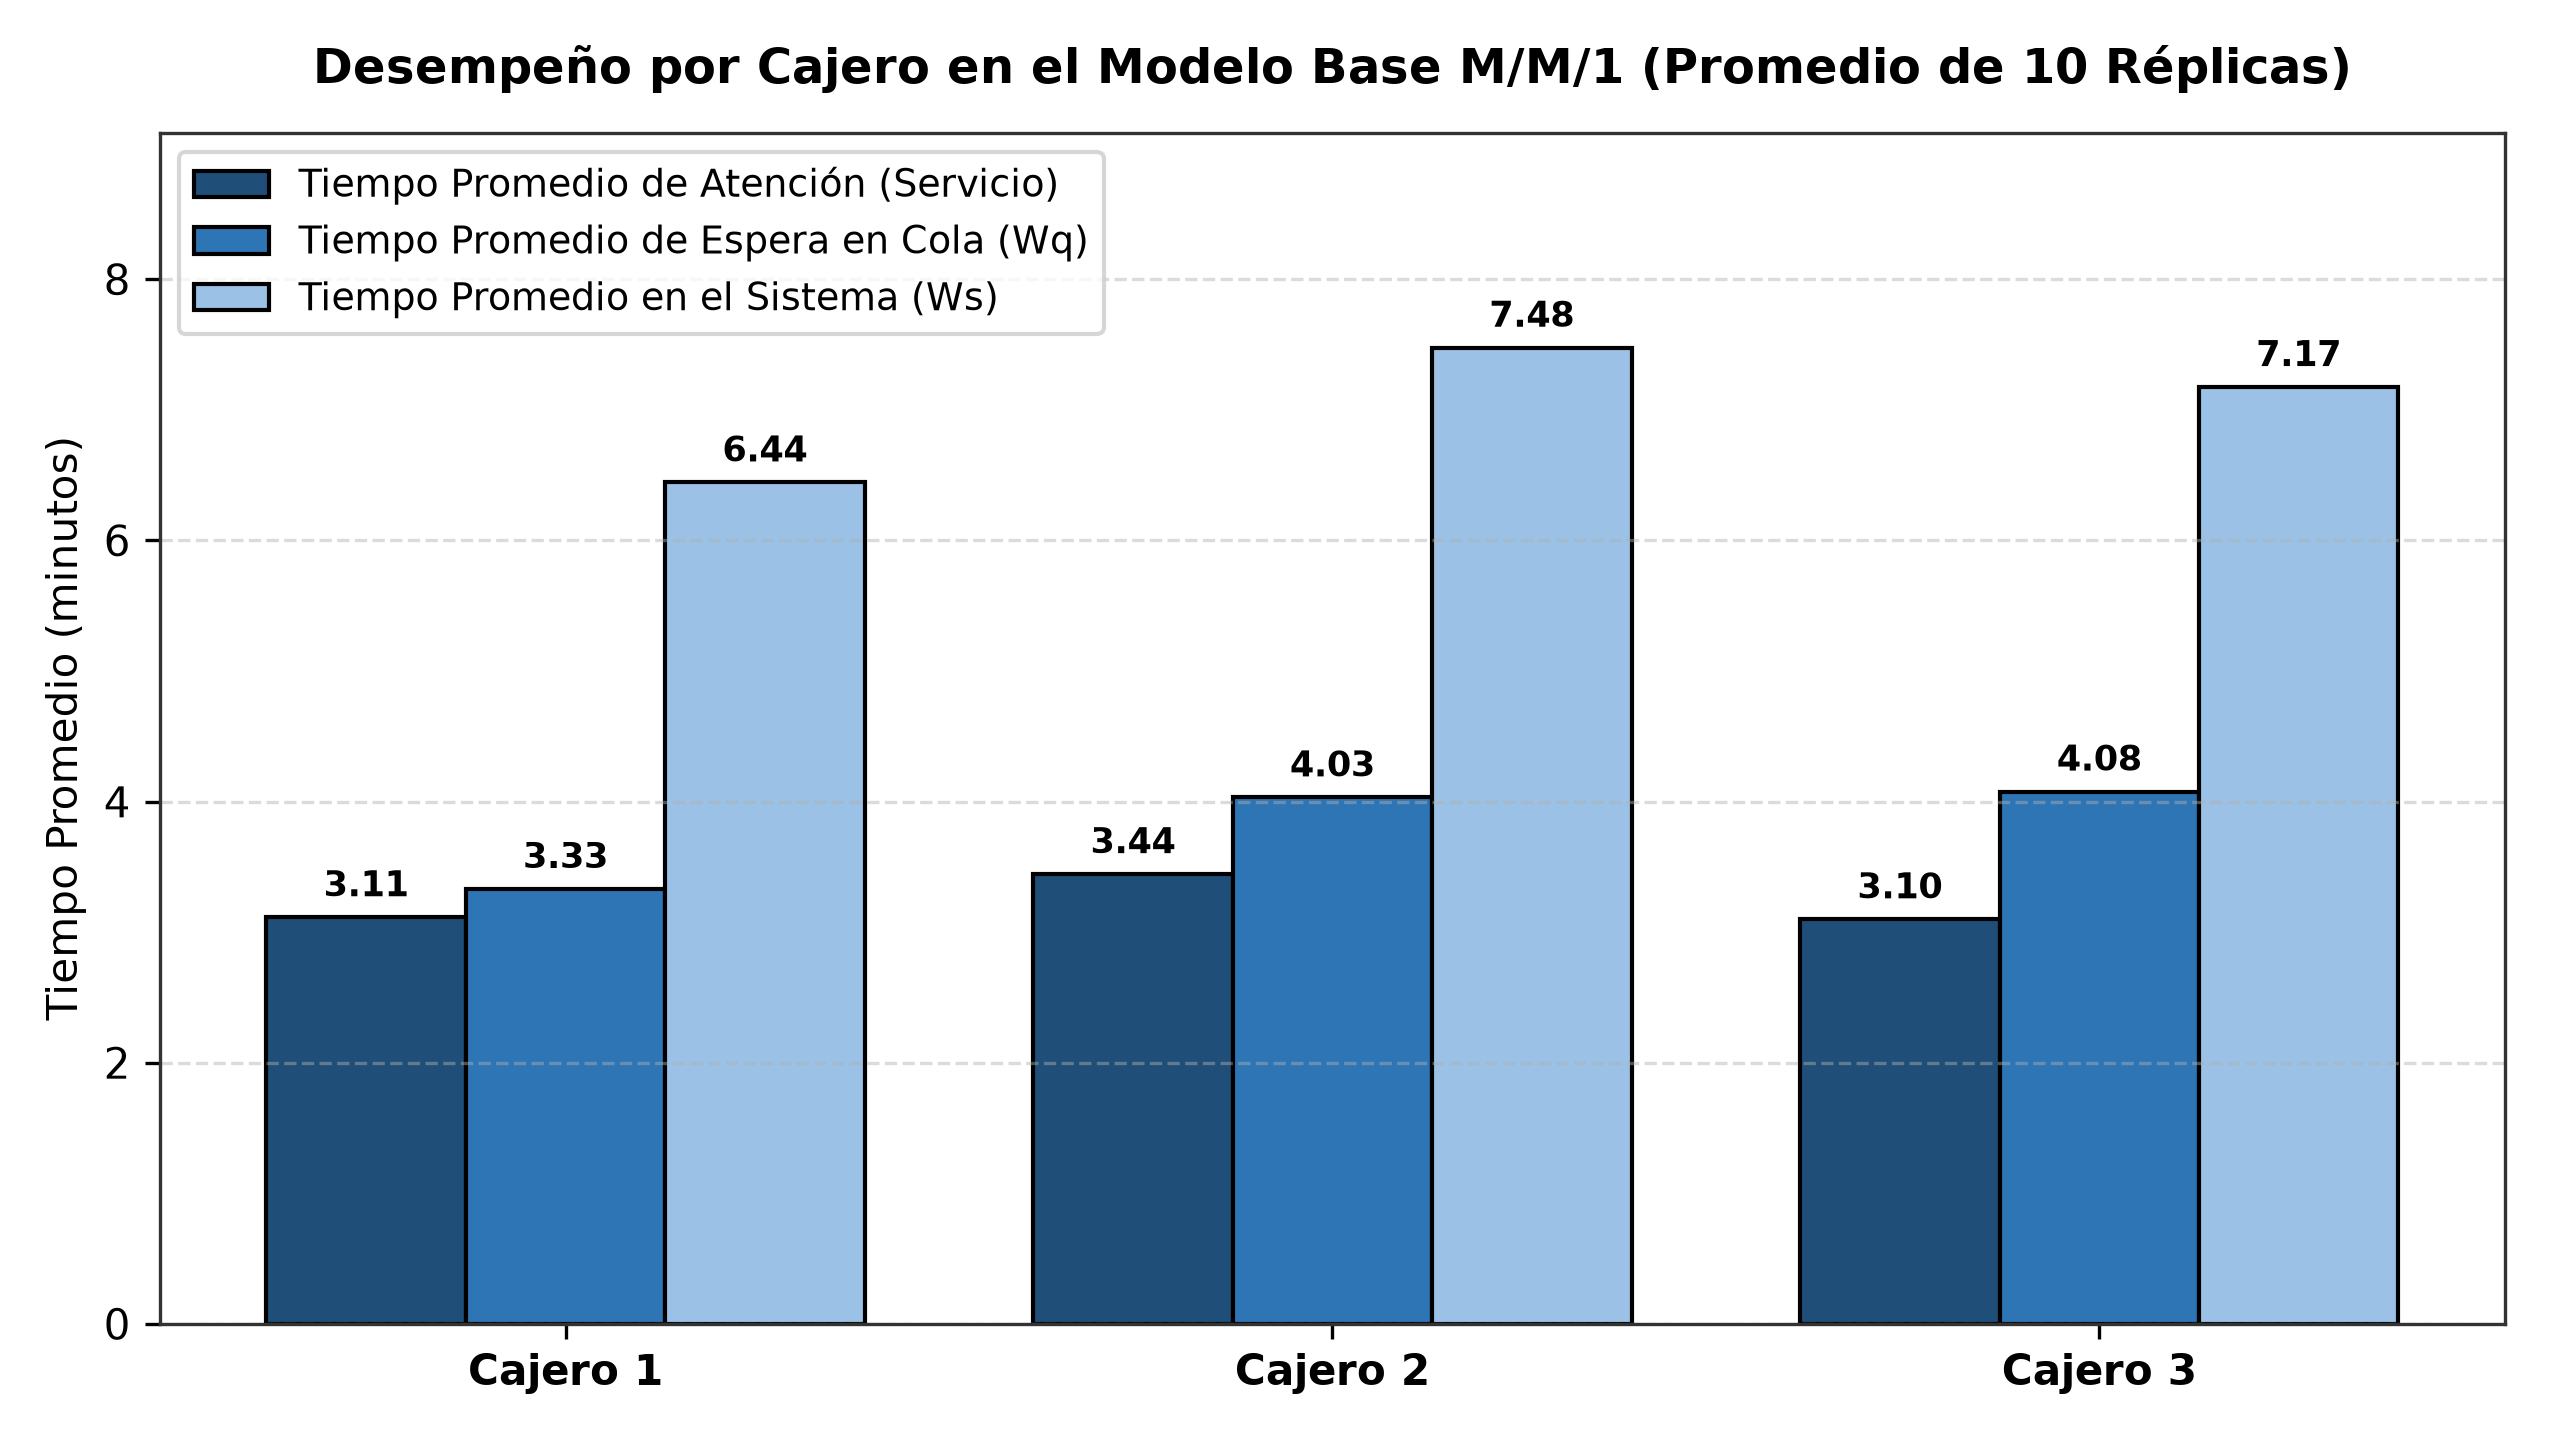

In [3]:
# 1. Estadísticas por réplica y cajero en el Modelo Base (sin segregar usuarios)
rep_cajero_base = (
    df_base.groupby(["replica", "cajero"])
    .agg(
        usuarios_atendidos=("id_cliente", "count"),
        tiempo_atencion_prom=("tiempo_servicio", "mean"),
        tiempo_espera_prom=("tiempo_espera", "mean"),
        tiempo_sistema_prom=("tiempo_sistema", "mean"),
        tiempo_ocupado_total=("tiempo_servicio", "sum"),
    )
    .reset_index()
)

rep_cajero_base["utilizacion_pct"] = (
    rep_cajero_base["tiempo_ocupado_total"] / TIEMPO_SIMULACION_MIN
) * 100.0


# 2. Consolidado de las 10 réplicas por cajero
tabla_punto1_cajeros = (
    rep_cajero_base.groupby("cajero")
    .agg(
        usuarios_prom_replica=("usuarios_atendidos", "mean"),
        usuarios_total_10rep=("usuarios_atendidos", "sum"),
        atencion_media_min=("tiempo_atencion_prom", "mean"),
        atencion_std_min=("tiempo_atencion_prom", "std"),
        atencion_min_rep=("tiempo_atencion_prom", "min"),
        atencion_max_rep=("tiempo_atencion_prom", "max"),
        espera_media_min=("tiempo_espera_prom", "mean"),
        sistema_media_min=("tiempo_sistema_prom", "mean"),
        utilizacion_media_pct=("utilizacion_pct", "mean"),
    )
    .reset_index()
)


# 3. Identificación automática del cajero con menor y mayor tiempo promedio de atención
fila_menor = tabla_punto1_cajeros.loc[tabla_punto1_cajeros["atencion_media_min"].idxmin()]
fila_mayor = tabla_punto1_cajeros.loc[tabla_punto1_cajeros["atencion_media_min"].idxmax()]

print("=== ESTADÍSTICAS POR CAJERO (10 RÉPLICAS - SIN SEGREGAR USUARIOS) ===")
print(tabla_punto1_cajeros.round(2).to_string(index=False))
print("-" * 75)
print(f"-> Cajero con MENOR tiempo promedio de atención: {fila_menor['cajero']} ({fila_menor['atencion_media_min']:.2f} min)")
print(f"-> Cajero con MAYOR tiempo promedio de atención: {fila_mayor['cajero']} ({fila_mayor['atencion_media_min']:.2f} min)")


# 4. Gráfica del Punto 1
fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=150)
x = np.arange(len(tabla_punto1_cajeros["cajero"]))
width = 0.26

b1 = ax.bar(x - width, tabla_punto1_cajeros["atencion_media_min"], width, label="Tiempo Promedio de Atención (Servicio)", color="#1f4e78", edgecolor="black")
b2 = ax.bar(x,         tabla_punto1_cajeros["espera_media_min"],   width, label="Tiempo Promedio de Espera en Cola (Wq)", color="#2e75b6", edgecolor="black")
b3 = ax.bar(x + width, tabla_punto1_cajeros["sistema_media_min"],  width, label="Tiempo Promedio en el Sistema (Ws)",     color="#9bc2e6", edgecolor="black")

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.2f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_title("Desempeño por Cajero en el Modelo Base M/M/1 (Promedio de 10 Réplicas)", fontsize=11.5, fontweight="bold", pad=12)
ax.set_ylabel("Tiempo Promedio (minutos)")
ax.set_xticks(x)
ax.set_xticklabels(tabla_punto1_cajeros["cajero"], fontweight="bold")
ax.set_ylim(0, max(tabla_punto1_cajeros["sistema_media_min"]) * 1.22)
ax.grid(axis="y", linestyle="--", alpha=0.45)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

---
## Punto 2: Promedio de Usuarios de Cada Tipo en la Totalidad de Cajeros

> **Enunciado:** *"Establece el promedio de usuarios de cada tipo en la totalidad de cajeros."*

En esta celda calculamos el promedio diario de usuarios en la totalidad de las 3 cajas tanto para los **4 tipos generales de velocidad** (`Rápido`, `Normal`, `Lento`, `Muy lento`) como para las **8 subcategorías combinadas** (`Tipo de acción` $\times$ `Tipo de usuario`), contrastando los porcentajes empíricos obtenidos con los porcentajes teóricos de las Tablas 1 y 2.

=== TABLA 2A: PROMEDIO DE USUARIOS POR TIPO EN LA TOTALIDAD DE CAJEROS ===
Tipo de Usuario  Total Usuarios (10 Réplicas)  Promedio por Réplica (3 Cajeros)  Desv. Estándar entre Réplicas  Promedio por Cajero por Réplica  Porcentaje Empírico (%)  Porcentaje Teórico (%)
         Rápido                           415                              41.5                           6.69                            13.83                    20.56                    19.1
         Normal                           631                              63.1                           9.98                            21.03                    31.27                    34.0
          Lento                           438                              43.8                           6.55                            14.60                    21.70                    20.9
      Muy lento                           534                              53.4                           4.84                            17.80          

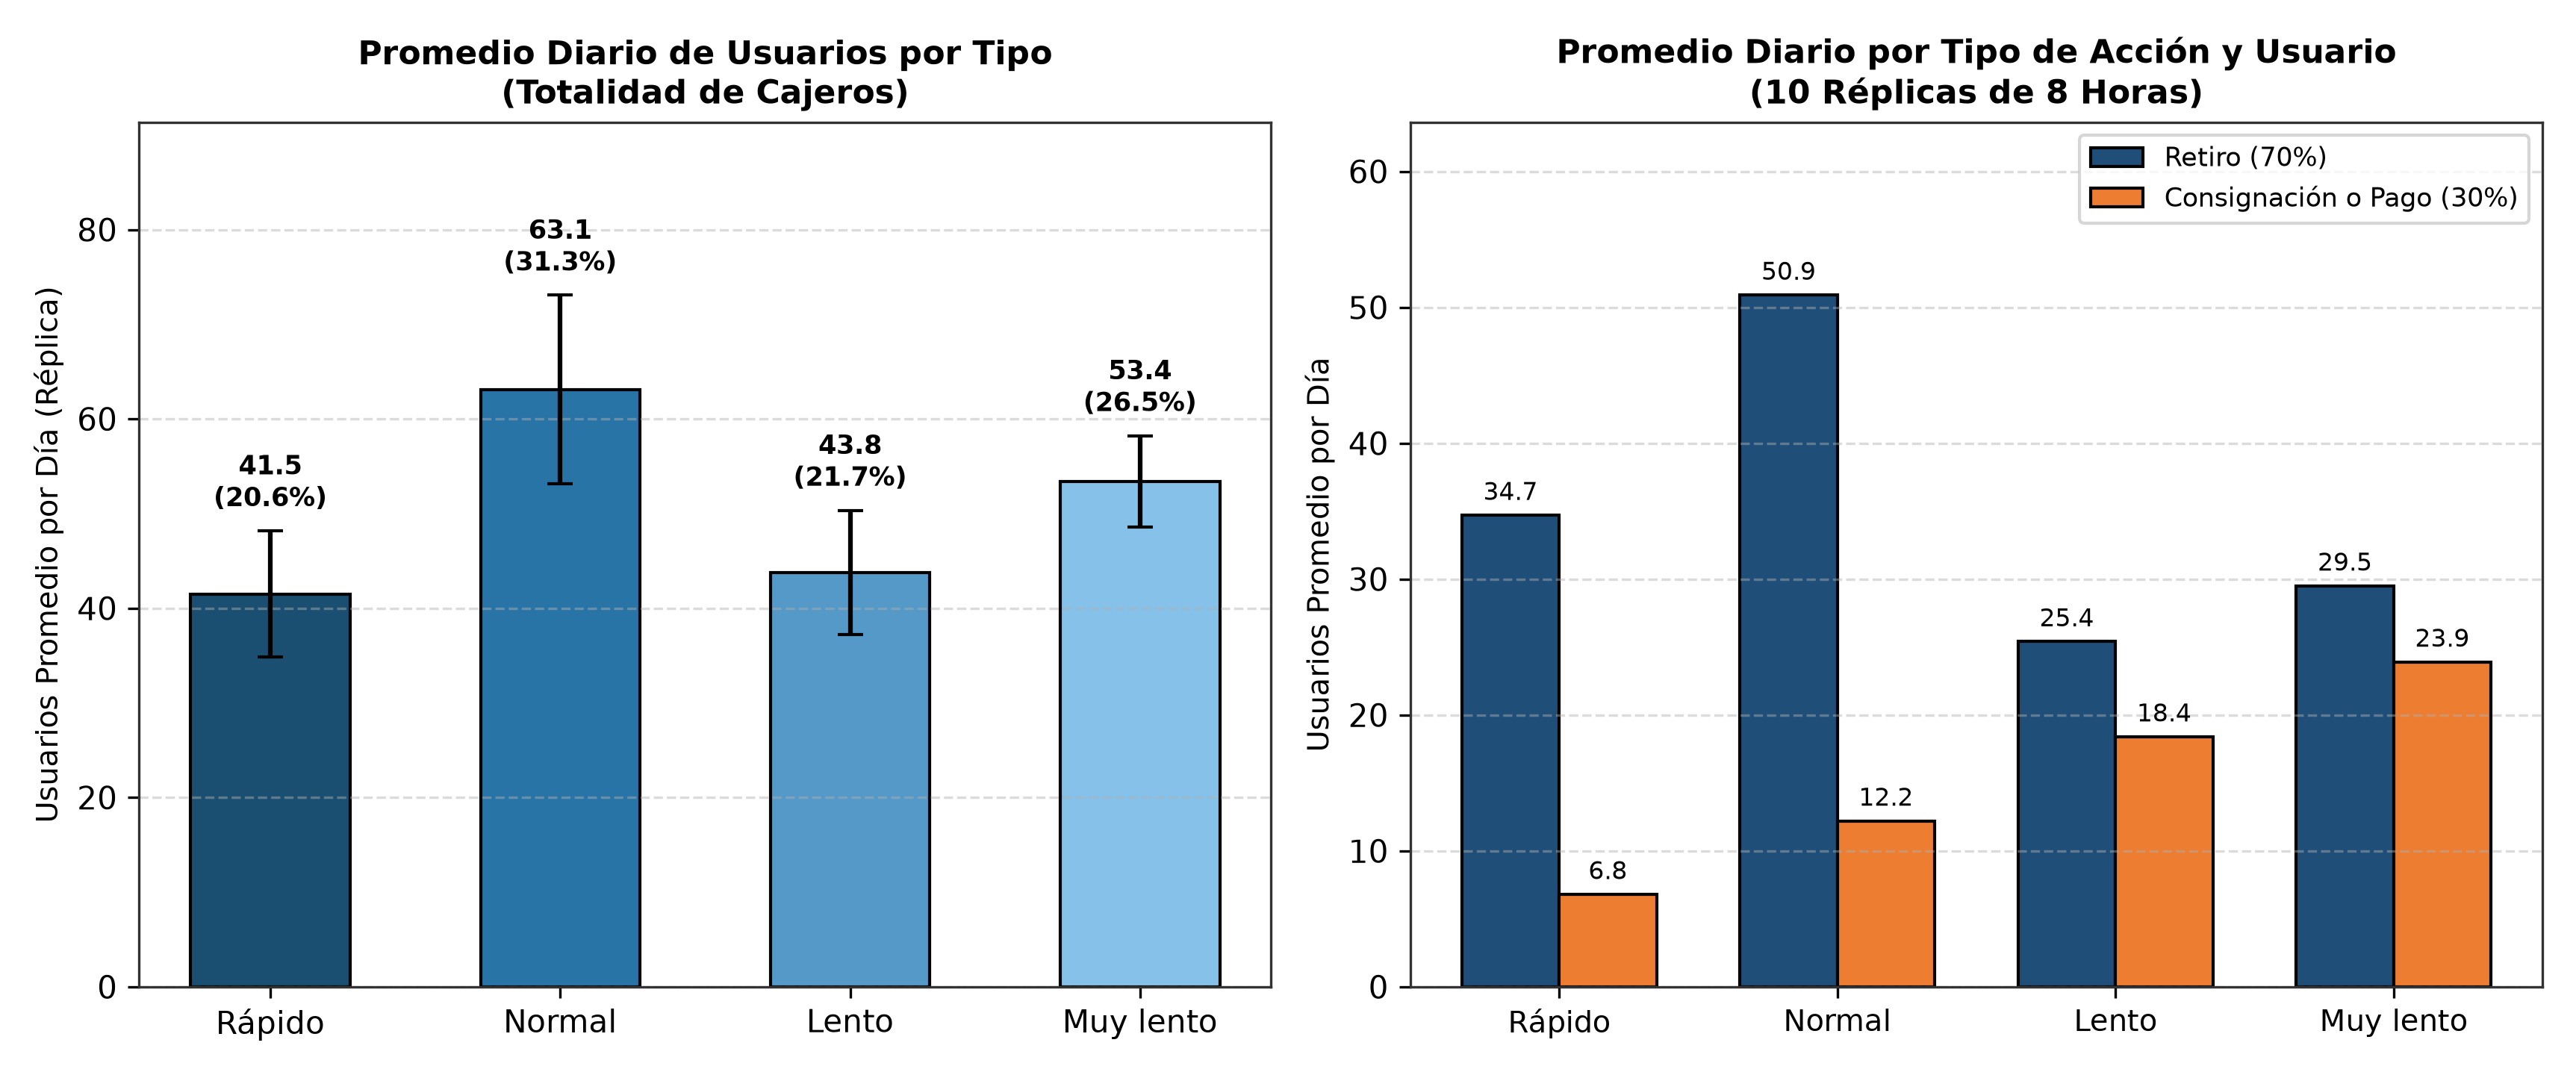

In [4]:
# 1. Conteo por réplica y por tipo de velocidad (Rápido, Normal, Lento, Muy lento)
conteo_tipo_rep = (
    df_base.groupby(["replica", "tipo_usuario"])["id_cliente"]
    .count()
    .unstack(fill_value=0)
    .reindex(columns=TIPOS_USUARIO_ORDEN, fill_value=0)
)
conteo_tipo_rep["Total_Replica"] = conteo_tipo_rep.sum(axis=1)


# 2. Tabla resumen para los 4 tipos de usuario en la totalidad de cajeros
resumen_punto2_tipo = pd.DataFrame({
    "Tipo de Usuario": TIPOS_USUARIO_ORDEN,
    "Total (10 Réplicas)": [int(conteo_tipo_rep[t].sum()) for t in TIPOS_USUARIO_ORDEN],
    "Promedio Diario (3 Cajeros)": [conteo_tipo_rep[t].mean() for t in TIPOS_USUARIO_ORDEN],
    "Desv. Estándar": [conteo_tipo_rep[t].std() for t in TIPOS_USUARIO_ORDEN],
    "Promedio por Cajero": [conteo_tipo_rep[t].mean() / NUM_CAJEROS_BASE for t in TIPOS_USUARIO_ORDEN],
    "Porcentaje Empírico (%)": [
        (conteo_tipo_rep[t].sum() / conteo_tipo_rep["Total_Replica"].sum()) * 100.0
        for t in TIPOS_USUARIO_ORDEN
    ],
    "Porcentaje Teórico (%)": [19.10, 34.00, 20.90, 26.00],
})


# 3. Tabla desglosada por Acción (Retiro vs. Pago) y Tipo de Usuario (8 subcategorías)
df_base["accion_tipo"] = df_base["accion"] + " - " + df_base["tipo_usuario"]
orden_8_cat = [f"{acc} - {t}" for acc in ACCIONES_ORDEN for t in TIPOS_USUARIO_ORDEN]

conteo_8cat_rep = (
    df_base.groupby(["replica", "accion_tipo"])["id_cliente"]
    .count()
    .unstack(fill_value=0)
    .reindex(columns=orden_8_cat, fill_value=0)
)

filas_8cat = []
total_gen = len(df_base)

for acc in ACCIONES_ORDEN:
    for t in TIPOS_USUARIO_ORDEN:
        col = f"{acc} - {t}"
        p_teo = PROB_ACCION[acc] * PARAMETROS_USUARIOS[acc][t]["prob"] * 100.0
        sub_df = df_base[(df_base["accion"] == acc) & (df_base["tipo_usuario"] == t)]

        filas_8cat.append({
            "Tipo de Acción": acc,
            "Tipo de Usuario": t,
            "Total (10 Réplicas)": int(conteo_8cat_rep[col].sum()),
            "Promedio por Réplica": conteo_8cat_rep[col].mean(),
            "Desv. Estándar": conteo_8cat_rep[col].std(),
            "% Empírico": (conteo_8cat_rep[col].sum() / total_gen) * 100.0,
            "% Teórico": p_teo,
            "Atención Media (min)": sub_df["tiempo_servicio"].mean(),
        })

resumen_punto2_8cat = pd.DataFrame(filas_8cat)

print("=== TABLA 2A: PROMEDIO DE USUARIOS POR TIPO EN LA TOTALIDAD DE CAJEROS ===")
print(resumen_punto2_tipo.round(2).to_string(index=False))
print("\n=== TABLA 2B: DESGLOSE POR TIPO DE ACCIÓN Y TIPO DE USUARIO ===")
print(resumen_punto2_8cat.round(2).to_string(index=False))


# 4. Gráfica del Punto 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8), dpi=150)
colores_tipo = ["#1b4f72", "#2874a6", "#5499c7", "#85c1e9"]

bars1 = ax1.bar(
    resumen_punto2_tipo["Tipo de Usuario"],
    resumen_punto2_tipo["Promedio Diario (3 Cajeros)"],
    yerr=resumen_punto2_tipo["Desv. Estándar"],
    capsize=4,
    color=colores_tipo,
    edgecolor="black",
    width=0.55,
)

for bar, pct, std_val in zip(bars1, resumen_punto2_tipo["Porcentaje Empírico (%)"], resumen_punto2_tipo["Desv. Estándar"]):
    h = bar.get_height()
    ax1.annotate(f"{h:.1f}\n({pct:.1f}%)", xy=(bar.get_x() + bar.get_width() / 2, h + std_val), xytext=(0, 5), textcoords="offset points", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax1.set_title("Promedio Diario de Usuarios por Tipo\n(Totalidad de Cajeros)", fontweight="bold")
ax1.set_ylabel("Usuarios Promedio por Día (Réplica)")
ax1.set_ylim(0, max(resumen_punto2_tipo["Promedio Diario (3 Cajeros)"] + resumen_punto2_tipo["Desv. Estándar"]) * 1.25)
ax1.grid(axis="y", linestyle="--", alpha=0.45)

ret_vals = resumen_punto2_8cat[resumen_punto2_8cat["Tipo de Acción"] == "Retiro"]["Promedio por Réplica"].values
pag_vals = resumen_punto2_8cat[resumen_punto2_8cat["Tipo de Acción"] == "Consignación o pago"]["Promedio por Réplica"].values
x2 = np.arange(len(TIPOS_USUARIO_ORDEN))
w2 = 0.35

br = ax2.bar(x2 - w2 / 2, ret_vals, w2, label="Retiro (70%)", color="#1f4e78", edgecolor="black")
bp = ax2.bar(x2 + w2 / 2, pag_vals, w2, label="Consignación o Pago (30%)", color="#ed7d31", edgecolor="black")

for bars in [br, bp]:
    for bar in bars:
        h = bar.get_height()
        ax2.annotate(f"{h:.1f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.5)

ax2.set_title("Promedio Diario por Tipo de Acción y Usuario\n(10 Réplicas de 8 Horas)", fontweight="bold")
ax2.set_xticks(x2)
ax2.set_xticklabels(TIPOS_USUARIO_ORDEN)
ax2.set_ylabel("Usuarios Promedio por Día")
ax2.set_ylim(0, max(ret_vals) * 1.25)
ax2.grid(axis="y", linestyle="--", alpha=0.45)
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

---
## Punto 3: Total de Usuarios de Cada Tipo en Cada Réplica y Modelo con Menor Cantidad

> **Enunciado:** *"Determina el total de usuarios de cada tipo en cada una de las réplicas y detalla el modelo con menor cantidad de usuarios por tipo."*

En esta celda construimos la matriz completa de las **10 réplicas** (Réplica 1 a Réplica 10), identificamos en qué réplica ocurrió el menor volumen total de clientes (**Réplica 2 con 173 usuarios**) y detallamos las réplicas que registraron la menor cantidad de usuarios para cada tipo específico.

=== TOTAL DE USUARIOS POR TIPO EN CADA UNA DE LAS 10 RÉPLICAS ===
 Réplica  Rápido  Normal  Lento  Muy lento  Total_Replica  Retiros  Pagos
       1      43      49     45         56            193      126     67
       2      32      50     35         56            173      130     43
       3      43      69     49         57            218      160     58
       4      42      74     52         57            225      157     68
       5      41      50     37         61            189      126     63
       6      30      69     52         48            199      139     60
       7      44      63     42         53            202      140     62
       8      39      75     41         47            202      137     65
       9      50      68     36         47            201      141     60
      10      51      64     49         52            216      149     67
---------------------------------------------------------------------------
-> Corrida del modelo con MENOR cantidad tot

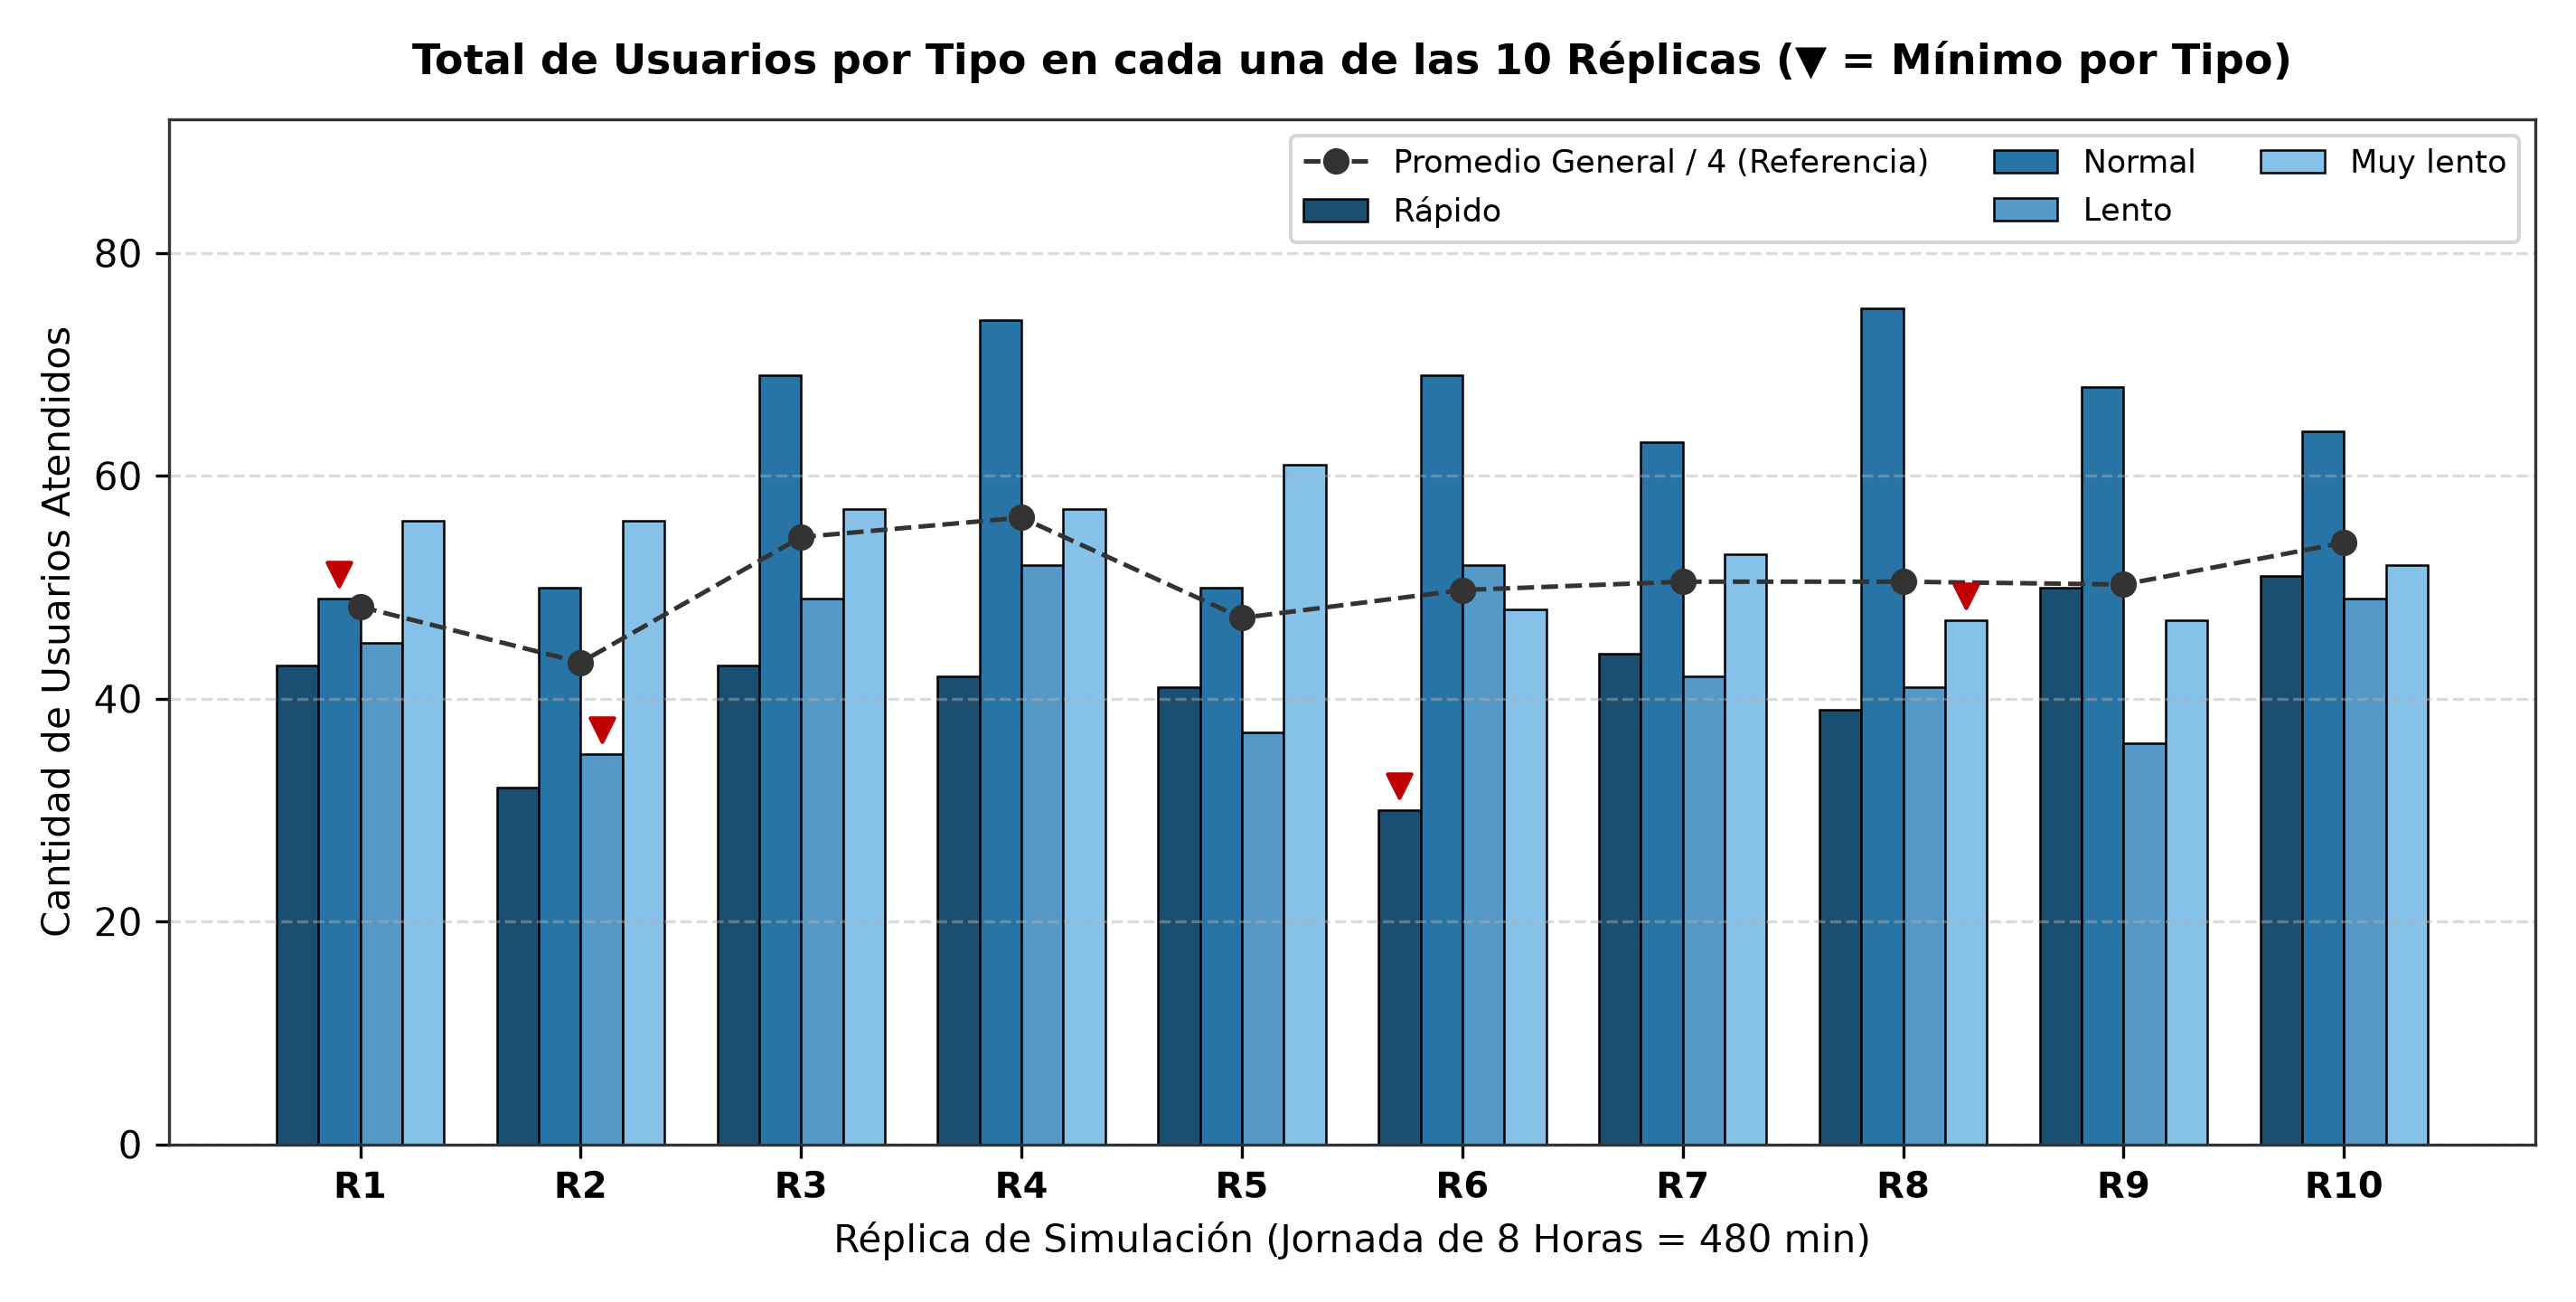

In [5]:
# 1. Construcción de la tabla detallada por cada una de las 10 réplicas
tabla_punto3_replicas = conteo_tipo_rep.copy()

conteo_accion_rep = (
    df_base.groupby(["replica", "accion"])["id_cliente"]
    .count()
    .unstack(fill_value=0)
    .reindex(columns=ACCIONES_ORDEN, fill_value=0)
)

tabla_punto3_replicas["Retiros"] = conteo_accion_rep["Retiro"]
tabla_punto3_replicas["Pagos"] = conteo_accion_rep["Consignación o pago"]
tabla_punto3_replicas.index.name = "Réplica"
tabla_punto3_replicas = tabla_punto3_replicas.reset_index()

print("=== TOTAL DE USUARIOS POR TIPO EN CADA UNA DE LAS 10 RÉPLICAS ===")
print(tabla_punto3_replicas.to_string(index=False))
print("-" * 75)


# 2. Detalle automático de la réplica/modelo con menor cantidad de usuarios por tipo
rep_min_total = tabla_punto3_replicas.loc[tabla_punto3_replicas["Total_Replica"].idxmin()]
print(f"-> Corrida del modelo con MENOR cantidad total de usuarios: Réplica {int(rep_min_total['Réplica'])} ({int(rep_min_total['Total_Replica'])} usuarios)")

for tipo in TIPOS_USUARIO_ORDEN:
    min_val = tabla_punto3_replicas[tipo].min()
    reps_min = tabla_punto3_replicas[tabla_punto3_replicas[tipo] == min_val]["Réplica"].tolist()
    reps_str = ", ".join([f"Réplica {r}" for r in reps_min])
    print(f"-> Menor cantidad de usuarios tipo '{tipo}': {min_val} usuarios (en {reps_str})")


# 3. Gráfica del Punto 3
fig, ax = plt.subplots(figsize=(9.5, 4.8), dpi=150)
replicas_labels = [f"R{r}" for r in tabla_punto3_replicas["Réplica"]]
x3 = np.arange(len(replicas_labels))
w3 = 0.19

for idx, (tipo, color) in enumerate(zip(TIPOS_USUARIO_ORDEN, colores_tipo)):
    offset = (idx - 1.5) * w3
    vals = tabla_punto3_replicas[tipo].values
    ax.bar(x3 + offset, vals, w3, label=tipo, color=color, edgecolor="black", linewidth=0.6)

    min_idx = int(np.argmin(vals))
    ax.scatter(x3[min_idx] + offset, vals[min_idx] + 2.2, color="#c00000", marker="v", s=40, zorder=5)

ax.plot(x3, tabla_punto3_replicas["Total_Replica"] / 4.0, linestyle="--", marker="o", color="#333333", linewidth=1.2, label="Promedio General / 4 (Referencia)")
ax.set_title("Total de Usuarios por Tipo en cada una de las 10 Réplicas (▼ = Mínimo por Tipo)", fontweight="bold", pad=12)
ax.set_xlabel("Réplica de Simulación (Jornada de 8 Horas = 480 min)")
ax.set_ylabel("Cantidad de Usuarios Atendidos")
ax.set_xticks(x3)
ax.set_xticklabels(replicas_labels, fontweight="bold")
ax.set_ylim(0, 92)
ax.grid(axis="y", linestyle="--", alpha=0.45)
ax.legend(frameon=True, ncol=3, fontsize=8.5, loc="upper right")
plt.tight_layout()
plt.show()

---
## Puntos 4 y 5: Evaluación de Creación de un Nuevo Cajero y Asignación Exclusiva de Cajas

> **Punto 4:** *"Define si es necesario crear un nuevo cajero utilizando los tiempos promedio de espera en todos los criterios del modelo."*  
> **Punto 5:** *"Decide cuántos cajeros deben ofrecer atención exclusiva para pagos y cuántos para retiros."*

En esta sección comparamos cuantitativamente los tiempos promedio de espera en cola ($W_q$), tiempos en el sistema ($W_s$) y porcentajes de utilización ($ho$) bajo los cuatro escenarios simulados.

=== COMPARACIÓN GLOBAL DE TIEMPOS DE ESPERA (PUNTOS 4 Y 5) ===
      escenario  usuarios_prom_dia  atencion_media_min  espera_global_min  espera_global_std  espera_retiros_min  espera_pagos_min  sistema_global_min  espera_maxima_prom_min
       3_Mixtos              201.8                3.21               3.83               0.62                3.81              3.89                7.03                   33.86
          2R_1P              201.8                3.21               4.24               1.85                1.60              9.97                7.45                   40.70
          1R_2P              201.8                3.21               4.60               1.70                5.42              2.63                7.81                   28.92
4_Cajeros_2R_2P              201.8                3.21               1.92               0.64                1.60              2.63                5.12                   23.69

=== DETALLE POR CAJERO EN CADA ESCENARIO ===
      escenario 

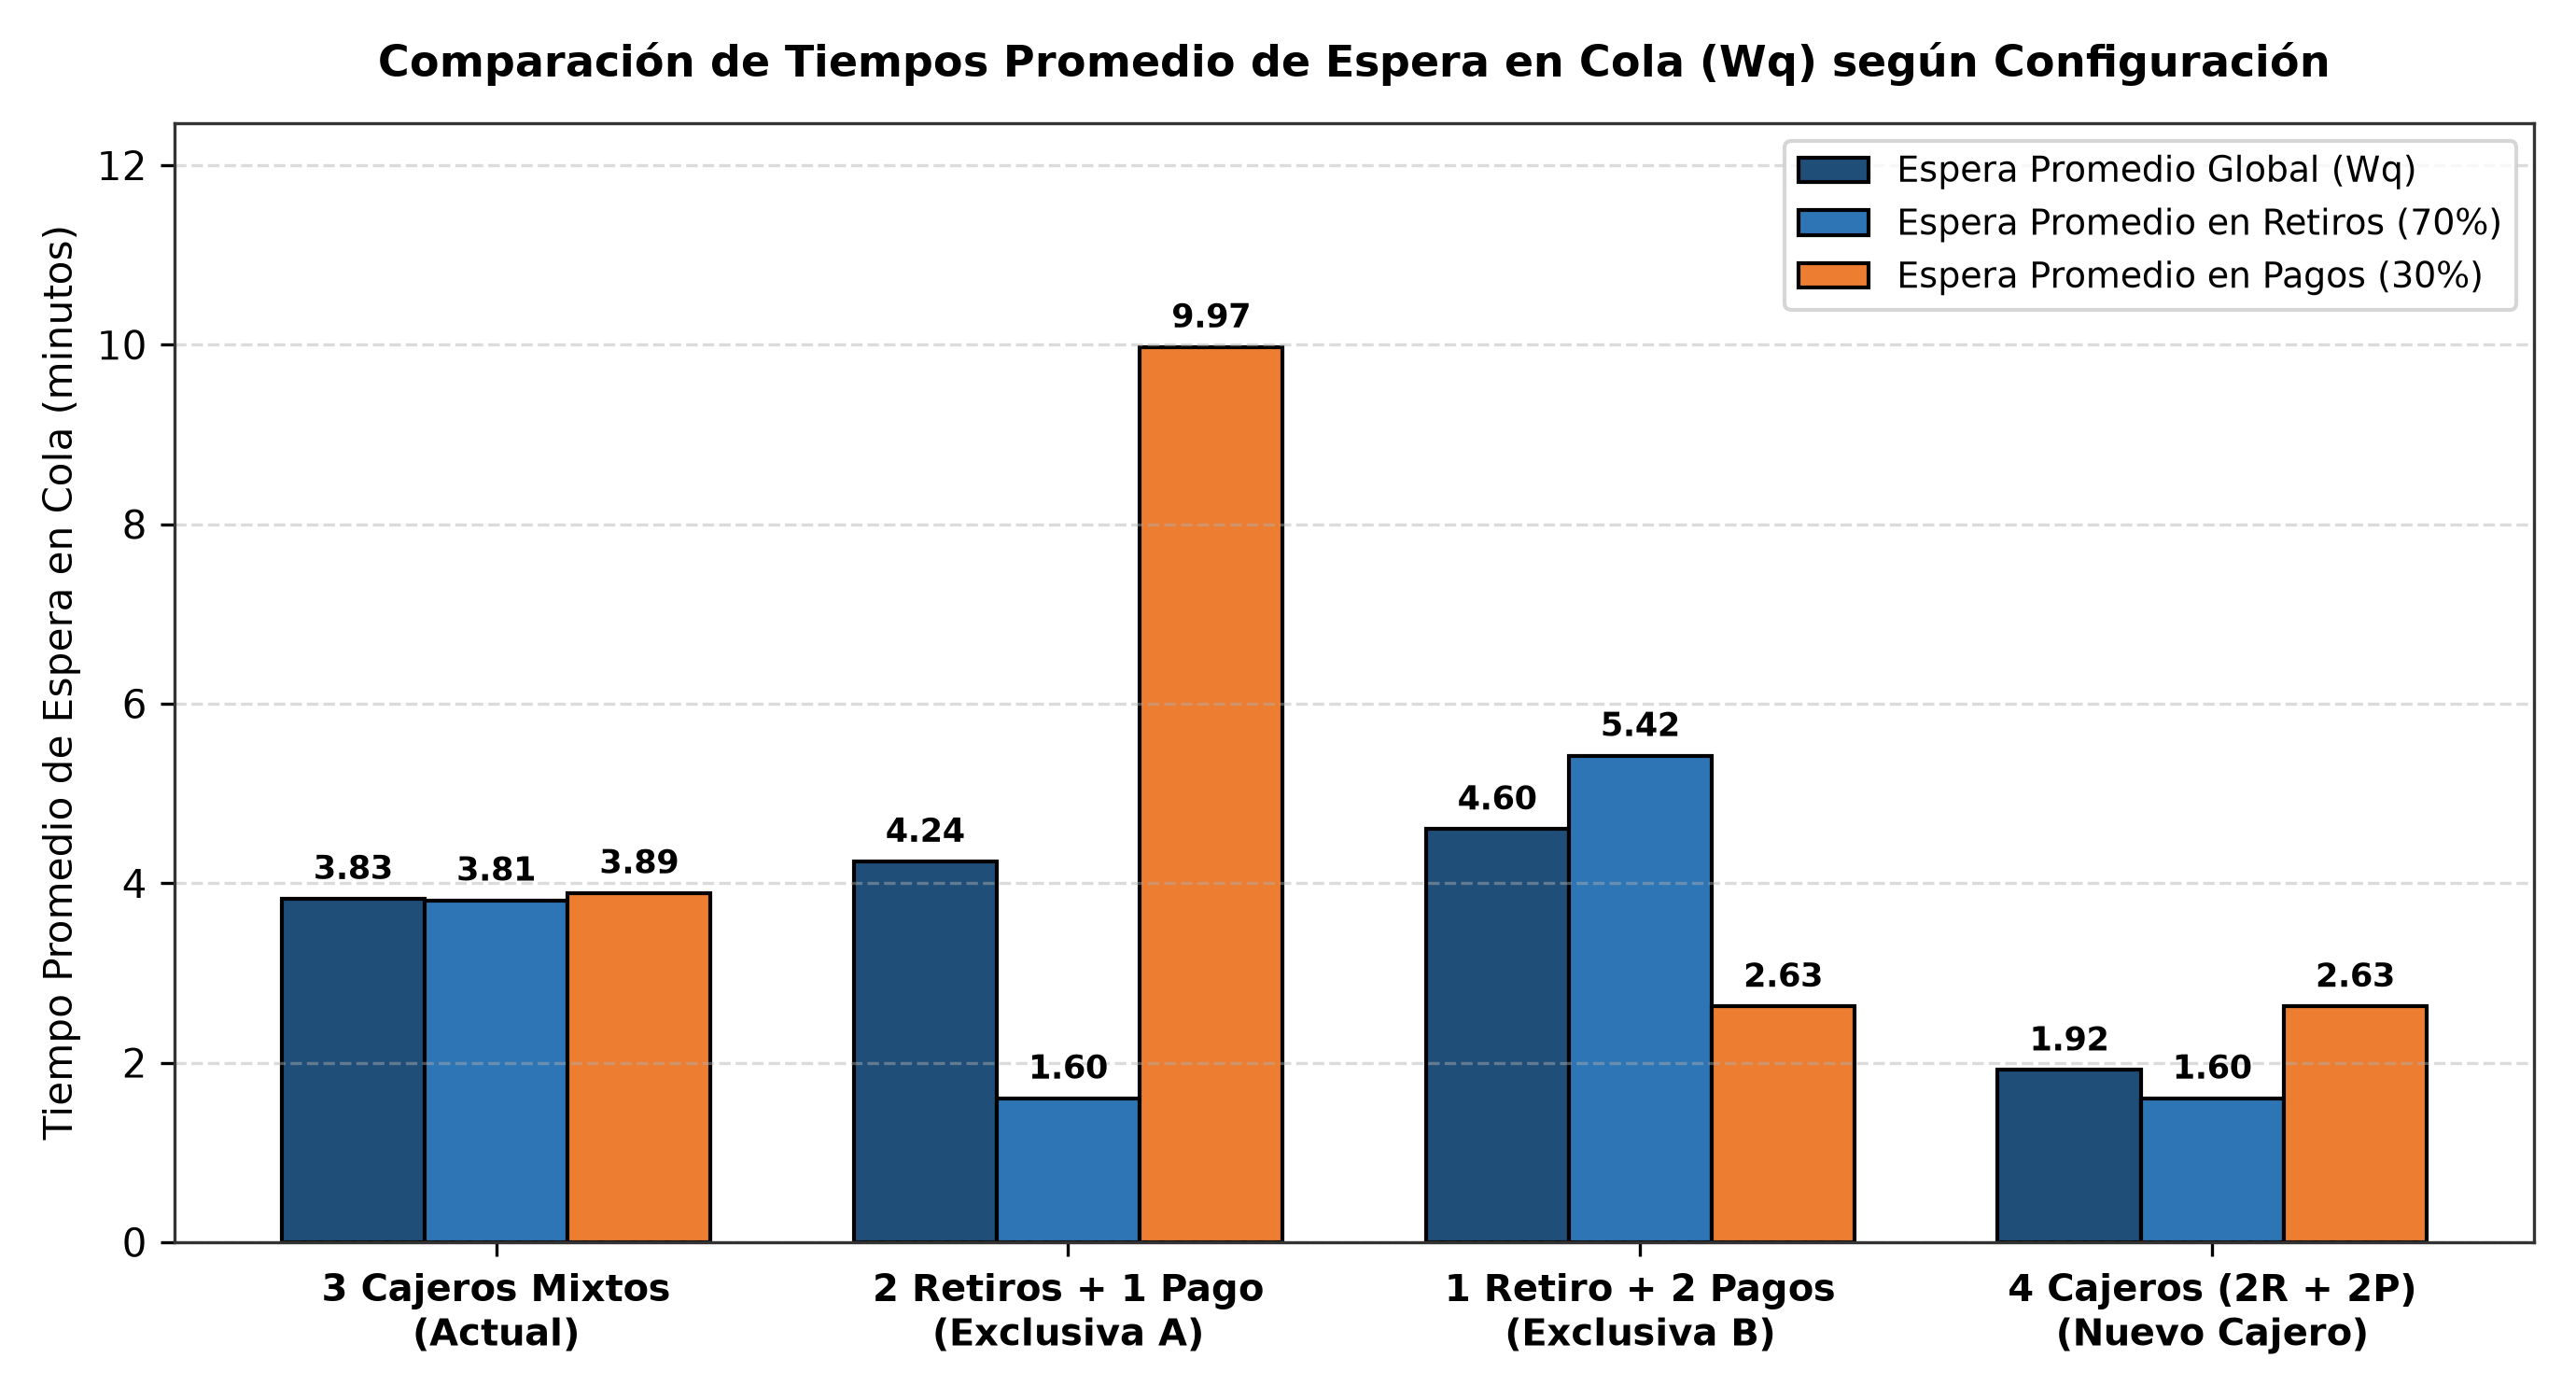

In [6]:
# 1. Desempeño detallado por cajero en cada escenario operativo
esc_cajero_rep = (
    df.groupby(["escenario", "replica", "cajero"])
    .agg(
        usuarios=("id_cliente", "count"),
        atencion_prom=("tiempo_servicio", "mean"),
        espera_prom=("tiempo_espera", "mean"),
        sistema_prom=("tiempo_sistema", "mean"),
        ocupacion_min=("tiempo_servicio", "sum"),
    )
    .reset_index()
)
esc_cajero_rep["utilizacion_pct"] = (esc_cajero_rep["ocupacion_min"] / TIEMPO_SIMULACION_MIN) * 100.0

tabla_escenarios_cajero = (
    esc_cajero_rep.groupby(["escenario", "cajero"])
    .agg(
        usuarios_prom_dia=("usuarios", "mean"),
        atencion_media_min=("atencion_prom", "mean"),
        espera_media_min=("espera_prom", "mean"),
        sistema_media_min=("sistema_prom", "mean"),
        utilizacion_media_pct=("utilizacion_pct", "mean"),
    )
    .reset_index()
)


# 2. Comparación global de tiempos promedio de espera en cola (Wq) por criterio
esc_global_rep = (
    df.groupby(["escenario", "replica"])
    .agg(
        usuarios_totales=("id_cliente", "count"),
        atencion_prom=("tiempo_servicio", "mean"),
        espera_prom_global=("tiempo_espera", "mean"),
        espera_max_global=("tiempo_espera", "max"),
        sistema_prom_global=("tiempo_sistema", "mean"),
    )
    .reset_index()
)

esc_accion_rep = (
    df.groupby(["escenario", "replica", "accion"])["tiempo_espera"]
    .mean()
    .unstack()
    .reset_index()
    .rename(columns={"Retiro": "espera_retiro_min", "Consignación o pago": "espera_pago_min"})
)

esc_merged = pd.merge(esc_global_rep, esc_accion_rep, on=["escenario", "replica"])

tabla_comparativa_escenarios = (
    esc_merged.groupby("escenario")
    .agg(
        usuarios_prom_dia=("usuarios_totales", "mean"),
        atencion_media_min=("atencion_prom", "mean"),
        espera_global_min=("espera_prom_global", "mean"),
        espera_global_std=("espera_prom_global", "std"),
        espera_retiros_min=("espera_retiro_min", "mean"),
        espera_pagos_min=("espera_pago_min", "mean"),
        sistema_global_min=("sistema_prom_global", "mean"),
        espera_maxima_prom_min=("espera_max_global", "mean"),
    )
    .reindex(["3_Mixtos", "2R_1P", "1R_2P", "4_Cajeros_2R_2P"])
    .reset_index()
)

print("=== COMPARACIÓN GLOBAL DE TIEMPOS DE ESPERA (PUNTOS 4 Y 5) ===")
print(tabla_comparativa_escenarios.round(2).to_string(index=False))
print("\n=== DETALLE POR CAJERO EN CADA ESCENARIO ===")
print(tabla_escenarios_cajero.round(2).to_string(index=False))


# 3. Gráfica comparativa de los Puntos 4 y 5
etiquetas_esc = [
    "3 Cajeros Mixtos\n(Actual)",
    "2 Retiros + 1 Pago\n(Exclusiva A)",
    "1 Retiro + 2 Pagos\n(Exclusiva B)",
    "4 Cajeros (2R + 2P)\n(Nuevo Cajero)",
]

fig, ax = plt.subplots(figsize=(9.2, 5.0), dpi=150)
x4 = np.arange(len(etiquetas_esc))
w4 = 0.25

b_glob = ax.bar(x4 - w4, tabla_comparativa_escenarios["espera_global_min"],  w4, label="Espera Promedio Global (Wq)",       color="#1f4e78", edgecolor="black")
b_ret  = ax.bar(x4,      tabla_comparativa_escenarios["espera_retiros_min"], w4, label="Espera Promedio en Retiros (70%)",  color="#2e75b6", edgecolor="black")
b_pag  = ax.bar(x4 + w4, tabla_comparativa_escenarios["espera_pagos_min"],   w4, label="Espera Promedio en Pagos (30%)",    color="#ed7d31", edgecolor="black")

for bars in [b_glob, b_ret, b_pag]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.2f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.set_title("Comparación de Tiempos Promedio de Espera en Cola (Wq) según Configuración", fontweight="bold", pad=12)
ax.set_ylabel("Tiempo Promedio de Espera en Cola (minutos)")
ax.set_xticks(x4)
ax.set_xticklabels(etiquetas_esc, fontweight="bold")
ax.set_ylim(0, max(tabla_comparativa_escenarios["espera_pagos_min"]) * 1.25)
ax.grid(axis="y", linestyle="--", alpha=0.45)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

---
## Síntesis de Respuestas y Conclusiones

1. **Cajero con menor y mayor tiempo promedio de atención (Punto 1):**
   * En el modelo base sin segregar usuarios (`3_Mixtos`), el **Cajero 3** registró el **menor tiempo promedio de atención** con **3,10 minutos** ($70.1\text{ usuarios/día}$), mientras que el **Cajero 2** presentó el **mayor tiempo promedio de atención** con **3,44 minutos** ($65.7\text{ usuarios/día}$; utilización del $46.58\%$).

2. **Promedio de usuarios de cada tipo en la totalidad de cajeros (Punto 2):**
   * Se atendieron en promedio **201,80 usuarios por día** ($2,018$ en las 10 réplicas): **41,50 Rápidos** ($20.56\%$), **63,10 Normales** ($31.27\%$), **43,80 Lentos** ($21.70\%$) y **53,40 Muy lentos** ($26.46\%$), distribuidos en **140,50 Retiros** ($69.62\%$) y **61,30 Consignaciones o pagos** ($30.38\%$).

3. **Total de usuarios por réplica y menor cantidad por tipo (Punto 3):**
   * La corrida con menor volumen global fue la **Réplica 2** con **173 usuarios** (donde también ocurrieron los mínimos de usuarios **Lentos** con $35$ y de **Pagos** con $43$). Los demás mínimos por tipo se presentaron en la **Réplica 6** para **Rápidos** ($30$), **Réplica 1** para **Normales** ($49$) y **Réplicas 8 y 9** para **Muy lentos** ($47$).

4. **¿Es necesario crear un nuevo cajero / cajero electrónico? (Punto 4):**
   * Aunque con 3 cajas el sistema es matemáticamente estable ($\rho < 1$), cualquier asignación exclusiva de 3 cajas genera un cuello de botella en la operación que queda con una sola caja (**9,97 min** de espera en pagos bajo `2R_1P` con $\rho = 66.08\%$, o **5,42 min** de espera en retiros bajo `1R_2P` con $\rho = 68.33\%$). Al incorporar un **4.º cajero / cajero electrónico (`4_Cajeros_2R_2P`)**, el tiempo promedio de espera global se reduce a **1,92 minutos** (**disminución del 54,8 %** frente a `2R_1P` y del **49,9 %** frente al esquema mixto), por lo que **sí es altamente recomendable y viable**.

5. **Decisión de cajeros exclusivos para pagos y para retiros (Punto 5):**
   * Con las 3 cajas actuales en modalidad exclusiva, se deben asignar **2 cajeros exclusivos para Retiros y 1 cajero exclusivo para Consignaciones o pagos (`2R_1P`)**, dado que obtiene un menor tiempo promedio de espera global (**4,24 min vs. 4,60 min** en `1R_2P`) y reduce el tiempo de espera del **70 % de los usuarios (Retiros)** a tan solo **1,60 minutos**.